# How curved are our datasets, and what kind of fault is each fault?

`main.ipynb` set the bar with simple detectors. This notebook asks two questions that decide where the project goes next:

1. **How curved are the links between sensors** in SKAB and Tennessee Eastman? If the links are straight lines, a curve-learning model has nothing extra to find there.
2. **What kind of fault is each fault?** Does it show in a single sensor, in many sensors, or only in the links between them?

The first run takes about 10 minutes. Answers are saved in `results/cache/`, so later runs are instant. To recompute a step, pass `refresh=True` to `structure.cached(...)`.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import numpy as np
import pandas as pd

from adlab import data, structure, simulate, plots

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_rows", 60)

tep, skab = data.load("tep"), data.load("skab")

## 1. The measure

For each sensor, we try to predict it from all the other sensors, using normal data only.

- First with a **straight-line model**. The share of the sensor's movement it explains is the *straight* share.
- Then a **flexible model** (boosted trees, which can follow curves) gets to explain whatever the straight-line model left over. The extra share it explains is the *curved* share.

Both are scored on stretches of time the models never saw. If the links are straight, the curved share is about zero. It can come out slightly below zero, because a flexible model fitted to pure noise makes predictions a little worse.

**Check on simulated data.** `simulate.linked_sensors` makes 8 sensors driven by two hidden factors, with a dial for how curved the links are. The measure should rise with the dial, and it does.

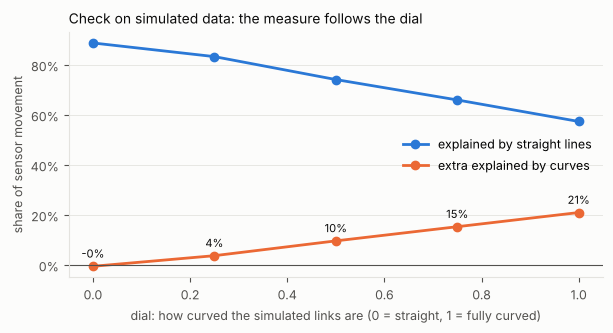

In [2]:
dial = structure.cached("dial_check", structure.dial_check)
plots.dial_check(dial);

## 2. How curved are the real datasets?

- **Tennessee Eastman:** the normal training run plus the normal test run, 1,460 readings of 52 variables.
- **SKAB, long normal run:** the 2.5-hour fault-free recording, 9,405 readings of 8 sensors.
- **SKAB, within sessions:** the first 400 normal seconds of each experiment, with each experiment's average removed. This takes out the slow warm-up that all sensors share, and leaves the links between their moment-to-moment movements.

,readings,sensors,straight share,curved share,"curved, low","curved, high",sensors with curved share over 0.05
Tennessee Eastman,1460.00,52.00,0.47,-0.03,-0.04,-0.03,0.00
"SKAB, long normal run",9405.00,8.00,0.31,0.02,-0.01,0.06,4.00
"SKAB, within sessions",13200.00,8.00,0.07,0.00,-0.02,0.02,1.00


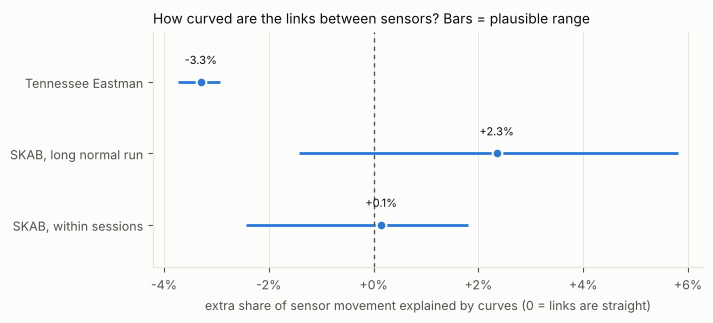

In [3]:
sensors = list(data.SKAB_INFO["sensor"])

def measure_all():
    within = np.vstack([r.fit - r.fit.mean(0) for r in skab.runs if len(r.fit) == 400])
    return {
        "Tennessee Eastman": structure.curvature_summary(
            np.vstack([tep.runs[0].fit, tep.val_normal[0].X]), data.TEP_CHANNELS),
        "SKAB, long normal run": structure.curvature_summary(
            data.skab_frame("anomaly-free/anomaly-free")[sensors].values, sensors),
        "SKAB, within sessions": structure.curvature_summary(within, sensors),
    }

curv = structure.cached("curvature", measure_all)
plots.curved_share(curv);
pd.DataFrame({k: {"readings": v["readings"], "sensors": v["sensors"], "straight share": v["straight"],
                  "curved share": v["curved"], "curved, low": v["curved_low"], "curved, high": v["curved_high"],
                  "sensors with curved share over 0.05": v["sensors_with_curved_over_5pts"]}
              for k, v in curv.items()}).T

**Reading this**

- **Tennessee Eastman: the links are straight.** Straight lines explain 47% of sensor movement on average, and curves add nothing (the curved share is slightly negative). Not one of the 52 variables gains more than 5 points from curves.
- **SKAB, long run: unclear.** Two vibration sensors gain about 21 points from curves, but the flow sensor gets far worse. The rig warms up during the recording, so each held-out stretch looks different from the rest, and a flexible model handles that badly.
- **SKAB, within sessions: the sensors are barely linked at all.** Straight lines explain only 7%, and curves add nothing. Most of the linking seen in the long run was the shared warm-up.

Two limits of this measure:
- It looks at links between readings taken at the same moment. It doesn't test delayed links.
- Both datasets were recorded in a single operating mode, so mode-dependent links can't show up.

In [4]:
# Per-sensor detail. Change the name to look at another dataset.
curv["SKAB, long normal run"]["table"]

,straight,curved
Accelerometer1RMS,-0.10,0.22
Accelerometer2RMS,0.03,0.21
Current,0.22,-0.01
Pressure,-0.00,-0.03
Temperature,0.70,0.08
Thermocouple,0.75,0.04
Voltage,0.22,0.07
Volume Flow RateRMS,0.63,-0.38


## 3. What kind of fault is each fault?

Each fault is scored by four families of checks, all at 1 false alarm in 100:

| Column | What looks at the data |
|---|---|
| level checks | Each sensor on its own: is its level unusual? (best of rolling z-score, EWMA, CUSUM) |
| straight links | Straight-line links between sensors (best of PCA and a new *straight-link residual* detector) |
| curved links | The same residual detector with a flexible model added |
| shape in time | Matrix Profile: is a sensor's recent shape unlike any normal shape? |

The *residual* detectors predict each sensor from the others and raise the alarm when a reading is far from its prediction.

*sensors moved* counts the sensors that are out of their own normal range for most of the fault.

In [5]:
types = structure.cached("fault_types", lambda: {"Tennessee Eastman": structure.fault_types(tep),
                                                 "SKAB": structure.fault_types(skab)})
for name, table in types.items():
    print(name, dict(table["kind"].value_counts()))
    display(table)

Tennessee Eastman {'single sensor': np.int64(9), 'many sensors': np.int64(7), 'hard for all': np.int64(3), 'hidden from level checks': np.int64(2)}


,level checks,straight links,curved links,shape in time,sensors moved,kind
kind of fault,,,,,,
01 step: A/C feed ratio,0.99,1.00,1.00,0.99,9.00,many sensors
02 step: B composition,0.98,0.99,0.99,0.98,17.00,many sensors
03 step: D feed temperature,0.40,0.02,0.03,0.04,0.00,hard for all
04 step: reactor cooling water temp,1.00,1.00,1.00,1.00,1.00,single sensor
05 step: condenser cooling water temp,0.97,1.00,1.00,0.68,1.00,single sensor
06 step: A feed loss,1.00,1.00,1.00,1.00,37.00,many sensors
07 step: C header pressure loss,1.00,1.00,1.00,1.00,1.00,single sensor
"08 random: A, B, C feed composition",0.98,0.98,0.97,0.98,33.00,many sensors
09 random: D feed temperature,0.04,0.02,0.02,0.01,0.00,hard for all


SKAB {'single sensor': np.int64(3), 'hard for all': np.int64(2), 'hidden from level checks': np.int64(2)}


,level checks,straight links,curved links,shape in time,sensors moved,kind
kind of fault,,,,,,
fluid leak or addition,0.50,0.68,0.60,0.65,1.00,single sensor
water level change,0.38,0.37,0.37,0.39,2.50,hard for all
cavitation,0.38,0.43,0.38,0.42,1.00,hard for all
hot water inflow,0.76,0.75,0.75,0.74,1.00,single sensor
rotor imbalance,0.80,0.80,0.80,0.77,1.80,single sensor
inlet valve closed,0.44,0.65,0.61,0.53,0.90,hidden from level checks
outlet valve closed,0.43,0.62,0.55,0.45,1.00,hidden from level checks


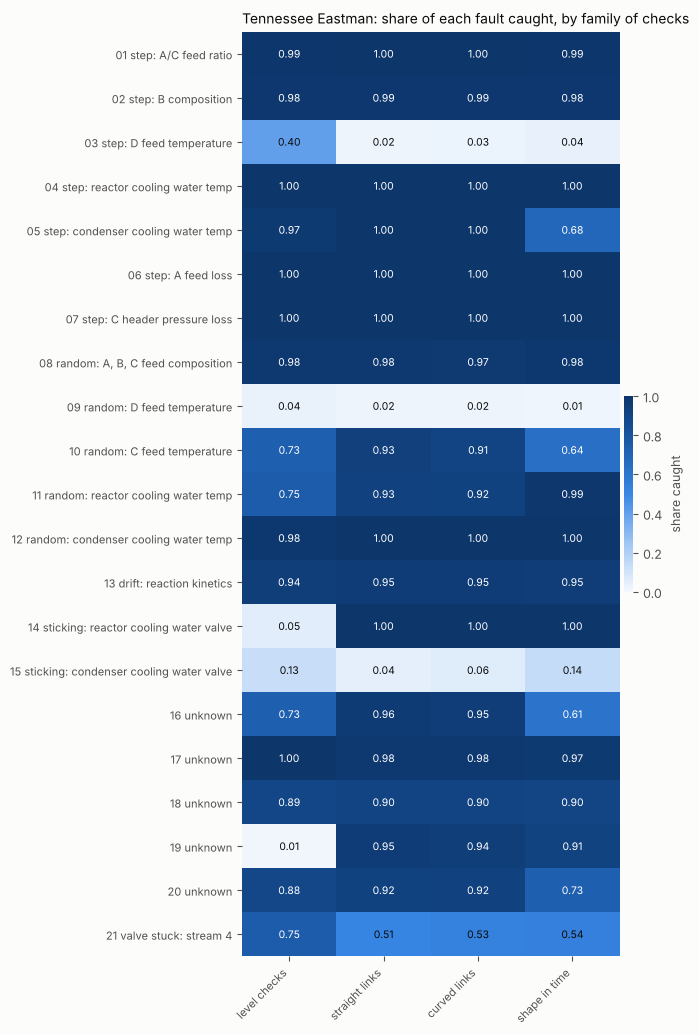

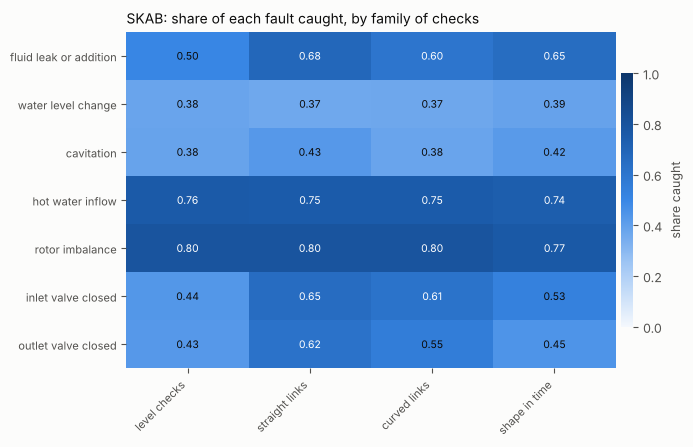

In [6]:
for name, table in types.items():
    plots.heatmap(table.drop(columns=["sensors moved", "kind"]), vmax=1, fmt="{:.2f}",
                  title=f"{name}: share of each fault caught, by family of checks", colorbar_label="share caught");

**Reading this**

- **Tennessee Eastman:** 16 of 21 faults are caught by per-sensor level checks. 9 of them move at most three sensors, and 7 move many.
- **Two faults (14 and 19) are invisible to level checks** but caught almost completely by link checks and by shape-in-time checks. Both make sensors oscillate inside their normal range.
- **Three faults (3, 9, 15) are hard for everything here.**
- **No fault needs curves.** On both datasets the curved-link column is never meaningfully above the straight-link column.
- **SKAB:** link checks help on the valve faults (about 0.65 against 0.44 for level checks). Water-level changes and cavitation stay hard.

## 4. Straight links against curved links, overall

Same detector, with and without the flexible model. The gap is curved minus straight; its range comes from resampling runs 1,000 times.

In [7]:
overall = structure.cached("link_overall", lambda: {"Tennessee Eastman": structure.link_detectors_overall(tep),
                                                    "SKAB": structure.link_detectors_overall(skab)})
pd.DataFrame({k: {"straight links": v["straight"], "curved links": v["curved"], "gap": v["gap"],
                  "gap, low": v["gap_ci"][0], "gap, high": v["gap_ci"][1]} for k, v in overall.items()}).T

,straight links,curved links,gap,"gap, low","gap, high"
Tennessee Eastman,0.81,0.81,-0.00,-0.00,0.00
SKAB,0.64,0.61,-0.04,-0.06,-0.01


**What this means for the project**

- **Curves buy nothing on either dataset.** On Tennessee Eastman the gap is zero to within half a point. On SKAB the curved version is a few points worse.
- So these two datasets **can't test the main claim** (H3: curves help once links are curved). They can test H1 and H2, and they're the "straight" end of the dial.
- **The straight-link residual detector is the new bar to beat:** it catches 81% on Tennessee Eastman and 64% on SKAB, against 76% and 56% for Matrix Profile. One caution: its settings were chosen after looking at these same test runs, so those numbers are optimistic until confirmed on fresh runs.

**Next:** build the full simulator with the curvature dial, and add a real dataset that has curved or mode-dependent links (the Cranfield multiphase flow rig and the multi-mode Tennessee Eastman data are the first candidates).